# UCS420 Assignment 8

In [1]:
import re
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)

Cleaned text:
 commercial aviation connects millions of people across continents every single day modern jet airliners rely on sophisticated flybywire flight control systems and turbofan engines for maximum fuel efficiency pilots and air traffic controllers coordinate constantly to maintain safe separation during all phases of flight advances in composite lightweight materials have made modern aircraft quieter and significantly more sustainable it isnt just about speed airline passenger safety and precision navigation remain the top priorities

Sentences (5):
 ['Commercial aviation connects millions of people across continents every single day.', 'Modern jet airliners rely on sophisticated fly-by-wire flight control systems and turbofan engines for maximum fuel efficiency.', 'Pilots and air traffic controllers coordinate constantly to maintain safe separation during all phases of flight.', 'Advances in composite lightweight materials have made modern aircraft quieter and significantly 

<Axes: title={'center': 'Top 10 Word Frequencies'}, xlabel='Samples', ylabel='Counts'>

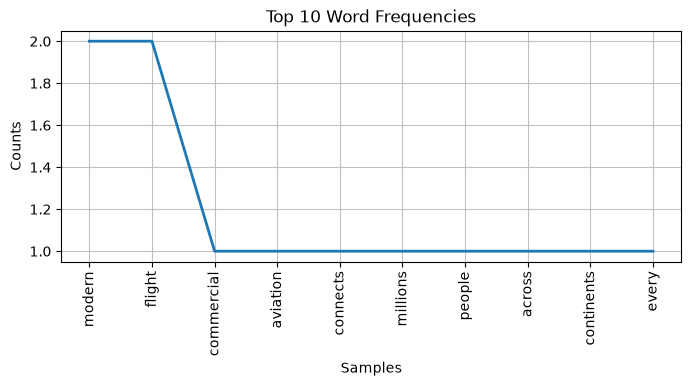

In [ ]:
# Q1
text = "Commercial aviation connects millions of people across continents every single day. Modern jet airliners rely on sophisticated fly-by-wire flight control systems and turbofan engines for maximum fuel efficiency. Pilots and air traffic controllers coordinate constantly to maintain safe separation during all phases of flight. Advances in composite lightweight materials have made modern aircraft quieter and significantly more sustainable. It isn't just about speed; airline passenger safety and precision navigation remain the top priorities."

# 1
cleaned_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned text:\n", cleaned_text)

# 2
sentences = sent_tokenize(text)
words = word_tokenize(text)
print(f"\nSentences ({len(sentences)}):\n", sentences)
print(f"\nWords ({len(words)}):\n", words)

# 3
py_split = text.split()
nltk_words = word_tokenize(text)
print("\nPython split():", py_split[:10])
print("NLTK word_tokenize():", nltk_words[:10])
# split() just breaks on whitespace so punctuation stays stuck to the words ('day.', 'speed;'). word_tokenize() isolates punctuation as separate tokens and also splits contractions properly like 'is' and 'n't'.
# so word_tokenize() seems better

# 4
stop_words = set(stopwords.words('english'))
words_no_stop = [w for w in word_tokenize(cleaned_text) if w not in stop_words]
print("\nWithout stopwords:\n", words_no_stop)

# 5
fdist = FreqDist(words_no_stop)
print("\nWord frequency distribution:")
print(fdist.most_common(10))

plt.figure(figsize=(8, 3))
fdist.plot(10, title="Top 10 Word Frequencies")

In [3]:
# Q2
# 1
words_alpha = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic words:\n", words_alpha)

# 2
words_alpha_no_stop = [w for w in words_alpha if w not in stop_words]
print("\nWithout stopwords:\n", words_alpha_no_stop)

# 3
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in words_alpha_no_stop]
print("\nStemmed words:\n", stemmed)

# 4
wnl = WordNetLemmatizer()
lemmatized = [wnl.lemmatize(w) for w in words_alpha_no_stop]
print("\nLemmatized words:\n", lemmatized)

# 5
comp_df = pd.DataFrame({
    'Word': words_alpha_no_stop,
    'Stemmed': stemmed,
    'Lemmatized': lemmatized
})
diff = comp_df[comp_df['Stemmed'] != comp_df['Lemmatized']].drop_duplicates()
print("\nDifferences between Stemmed and Lemmatized:")
print(diff.to_string(index=False))

# PorterStemmer blindly chops off prefixes/suffixes with heuristic rules, often leaving non-words like 'effici' or 'contin'. WordNetLemmatizer uses a dictionary to return actual base words (lemmas). Stemming is faster and good for search indexing where spelling doesn't matter, while lemmatization is better for things like sentiment analysis or chatbots where real words and meaning actually matter.

Alphabetic words:
 ['commercial', 'aviation', 'connects', 'millions', 'of', 'people', 'across', 'continents', 'every', 'single', 'day', 'modern', 'jet', 'airliners', 'rely', 'on', 'sophisticated', 'fly', 'by', 'wire', 'flight', 'control', 'systems', 'and', 'turbofan', 'engines', 'for', 'maximum', 'fuel', 'efficiency', 'pilots', 'and', 'air', 'traffic', 'controllers', 'coordinate', 'constantly', 'to', 'maintain', 'safe', 'separation', 'during', 'all', 'phases', 'of', 'flight', 'advances', 'in', 'composite', 'lightweight', 'materials', 'have', 'made', 'modern', 'aircraft', 'quieter', 'and', 'significantly', 'more', 'sustainable', 'it', 'isn', 't', 'just', 'about', 'speed', 'airline', 'passenger', 'safety', 'and', 'precision', 'navigation', 'remain', 'the', 'top', 'priorities']

Without stopwords:
 ['commercial', 'aviation', 'connects', 'millions', 'people', 'across', 'continents', 'every', 'single', 'day', 'modern', 'jet', 'airliners', 'rely', 'sophisticated', 'fly', 'wire', 'flight', 'c


Lemmatized words:
 ['commercial', 'aviation', 'connects', 'million', 'people', 'across', 'continent', 'every', 'single', 'day', 'modern', 'jet', 'airliner', 'rely', 'sophisticated', 'fly', 'wire', 'flight', 'control', 'system', 'turbofan', 'engine', 'maximum', 'fuel', 'efficiency', 'pilot', 'air', 'traffic', 'controller', 'coordinate', 'constantly', 'maintain', 'safe', 'separation', 'phase', 'flight', 'advance', 'composite', 'lightweight', 'material', 'made', 'modern', 'aircraft', 'quieter', 'significantly', 'sustainable', 'speed', 'airline', 'passenger', 'safety', 'precision', 'navigation', 'remain', 'top', 'priority']

Differences between Stemmed and Lemmatized:
         Word       Stemmed    Lemmatized
   commercial      commerci    commercial
     aviation         aviat      aviation
     connects       connect      connects
       people         peopl        people
   continents        contin     continent
        every         everi         every
       single         singl     

In [ ]:
# Q3
texts = [
    "Apple launched a new MacBook featuring superior battery efficiency and an OLED display.",
    "Nvidia announced high performance GPUs designed specifically for training artificial intelligence models.",
    "Sony revealed wireless noise cancelling headphones with exceptional sound clarity and comfort."
]

# 1
cv = CountVectorizer()
bow = cv.fit_transform(texts)
print("Vocabulary:\n", cv.get_feature_names_out())
print("\nBoW representation:\n", bow.toarray())

# 2
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)
feature_names = tfidf.get_feature_names_out()
print("\nTF-IDF scores:\n", tfidf_matrix.toarray().round(3))

# 3
print("\nTop 3 keywords from each text:")
for i, t in enumerate(texts):
    scores = tfidf_matrix.toarray()[i]
    top_indices = scores.argsort()[::-1][:3]
    top_words = [(feature_names[idx], round(scores[idx], 3)) for idx in top_indices]
    print(f"Text {i+1}: {top_words}")

# The top 3 keywords have the highest TF-IDF weights because these words occur specifically in their respective sentence and nowhere else across the three texts.

Vocabulary:
 ['an' 'and' 'announced' 'apple' 'artificial' 'battery' 'cancelling'
 'clarity' 'comfort' 'designed' 'display' 'efficiency' 'exceptional'
 'featuring' 'for' 'gpus' 'headphones' 'high' 'intelligence' 'launched'
 'macbook' 'models' 'new' 'noise' 'nvidia' 'oled' 'performance' 'revealed'
 'sony' 'sound' 'specifically' 'superior' 'training' 'wireless' 'with']

BoW representation:
 [[1 1 0 1 0 1 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 1 0 0 0]
 [0 0 1 0 1 0 0 0 0 1 0 0 0 0 1 1 0 1 1 0 0 1 0 0 1 0 1 0 0 0 1 0 1 0 0]
 [0 1 0 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 1]]

TF-IDF scores:
 [[0.294 0.224 0.    0.294 0.    0.294 0.    0.    0.    0.    0.294 0.294
  0.    0.294 0.    0.    0.    0.    0.    0.294 0.294 0.    0.294 0.
  0.    0.294 0.    0.    0.    0.    0.    0.294 0.    0.    0.   ]
 [0.    0.    0.289 0.    0.289 0.    0.    0.    0.    0.289 0.    0.
  0.    0.    0.289 0.289 0.    0.289 0.289 0.    0.    0.289 0.    0.
  0.289 0.    0.

In [ ]:
# Q4
text_ai = """Artificial intelligence allows machines to learn from patterns in historical data.
Machine learning models and neural networks process complex unstructured data like images and speech.
Deep learning architectures optimize decision making automatically without manual rule programming.
Modern artificial intelligence powers automated translation, robotics, and generative systems."""

text_bc = """Blockchain is a decentralized and distributed ledger that securely records transactional data.
Cryptographic hash functions link consecutive blocks to ensure records are immutable and tamper evident.
Consensus mechanisms like proof of work validate new network transactions across peer nodes.
Modern blockchain systems power smart contracts, digital assets, and decentralized finance protocols."""

# 1
clean_ai = re.sub(r'[^\w\s]', '', text_ai.lower())
clean_bc = re.sub(r'[^\w\s]', '', text_bc.lower())

tokens_ai = [w for w in word_tokenize(clean_ai) if w not in stop_words]
tokens_bc = [w for w in word_tokenize(clean_bc) if w not in stop_words]

print("Tokens AI:\n", tokens_ai)
print("\nTokens Blockchain:\n", tokens_bc)

# 2
# a
set_ai = set(tokens_ai)
set_bc = set(tokens_bc)
jaccard = len(set_ai & set_bc) / len(set_ai | set_bc)
print("\nShared words:", set_ai & set_bc)
print(f"Jaccard Similarity: {jaccard:.4f}")

# b
tfidf_pair = TfidfVectorizer()
vectors = tfidf_pair.fit_transform([text_ai, text_bc])
cos_sim = cosine_similarity(vectors[0:1], vectors[1:2])[0][0]
print(f"Cosine Similarity: {cos_sim:.4f}")

# c
# Cosine similarity gives better insights here. Jaccard only looks at the exact set overlap of words regardless of frequency or importance. Cosine with TF-IDF reduces the weights of common words and evaluates the directional similarity of the document vectors.

Tokens AI:
 ['artificial', 'intelligence', 'allows', 'machines', 'learn', 'patterns', 'historical', 'data', 'machine', 'learning', 'models', 'neural', 'networks', 'process', 'complex', 'unstructured', 'data', 'like', 'images', 'speech', 'deep', 'learning', 'architectures', 'optimize', 'decision', 'making', 'automatically', 'without', 'manual', 'rule', 'programming', 'modern', 'artificial', 'intelligence', 'powers', 'automated', 'translation', 'robotics', 'generative', 'systems']

Tokens Blockchain:
 ['blockchain', 'decentralized', 'distributed', 'ledger', 'securely', 'records', 'transactional', 'data', 'cryptographic', 'hash', 'functions', 'link', 'consecutive', 'blocks', 'ensure', 'records', 'immutable', 'tamper', 'evident', 'consensus', 'mechanisms', 'like', 'proof', 'work', 'validate', 'new', 'network', 'transactions', 'across', 'peer', 'nodes', 'modern', 'blockchain', 'systems', 'power', 'smart', 'contracts', 'digital', 'assets', 'decentralized', 'finance', 'protocols']

Shared wor

                                                                                              Review  Polarity  Subjectivity Sentiment
          The noise cancelling headphones have outstanding sound clarity and battery life is superb.     0.633         0.758  Positive
         Extremely comfortable ear cushions and wonderful build quality for long listening sessions.     0.450         0.733  Positive
Customer service was terrible and the headphones arrived completely damaged with poor sound quality.    -0.225         0.600  Negative
                             The package arrived on Monday and contains the standard charging cable.     0.000         0.000   Neutral


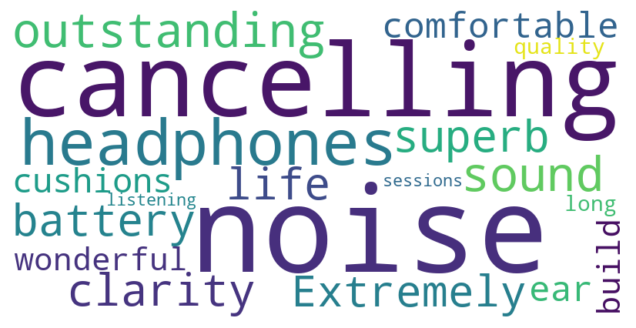

In [6]:
# Q5
reviews = [
    "The noise cancelling headphones have outstanding sound clarity and battery life is superb.",
    "Extremely comfortable ear cushions and wonderful build quality for long listening sessions.",
    "Customer service was terrible and the headphones arrived completely damaged with poor sound quality.",
    "The package arrived on Monday and contains the standard charging cable."
]

# 1 & 2
rows = []
for r in reviews:
    blob = TextBlob(r)
    pol = blob.sentiment.polarity
    sub = blob.sentiment.subjectivity
    if pol > 0.1:
        sentiment = "Positive"
    elif pol < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
    rows.append({'Review': r, 'Polarity': round(pol, 3), 'Subjectivity': round(sub, 3), 'Sentiment': sentiment})

df_reviews = pd.DataFrame(rows)
print(df_reviews.to_string(index=False))

# 3
pos_reviews = [r['Review'] for r in rows if r['Sentiment'] == 'Positive']
pos_text = " ".join(pos_reviews)

wc = WordCloud(width=800, height=400, background_color="white").generate(pos_text)

plt.figure(figsize=(8, 4))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

In [7]:
# Q6
text_corpus = """Artificial intelligence and machine learning are transforming modern technology at a rapid pace. Machine learning algorithms discover patterns in large datasets and use them to make smart predictions. Deep learning models rely on neural networks to process language, voice, and visual data with remarkable accuracy. As computers learn from experience, intelligent systems become faster and more capable of solving complex problems. Data science combines mathematics, statistics, and programming to build automated workflows. With continuous advancements in computational power and cloud infrastructure, artificial intelligence will continue to shape software development, scientific research, and human everyday life."""

# 1
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text_corpus])
total_words = len(tokenizer.word_index) + 1
print(f"Total words in vocabulary: {total_words}")

# 2
input_sequences = []
token_list = tokenizer.texts_to_sequences([text_corpus])[0]
for i in range(1, len(token_list)):
    n_gram_seq = token_list[:i+1]
    input_sequences.append(n_gram_seq)

max_seq_len = max([len(x) for x in input_sequences])
padded_sequences = np.array(pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre'))

X, y = padded_sequences[:, :-1], padded_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 3
model.fit(X, y, epochs=120, verbose=0)

def generate_line(seed, num_words=8):
    output_text = seed
    for _ in range(num_words):
        toks = tokenizer.texts_to_sequences([output_text])[0]
        toks = pad_sequences([toks], maxlen=max_seq_len-1, padding='pre')
        pred = model.predict(toks, verbose=0)
        next_word = tokenizer.index_word.get(np.argmax(pred), '')
        output_text += " " + next_word
    return output_text

print("Line 1:", generate_line("machine", 8))
print("Line 2:", generate_line("artificial", 8))
print("Line 3:", generate_line("deep", 8))

Total words in vocabulary: 79


Line 1: machine and intelligence machine learning machine learning modern at
Line 2: artificial intelligence and machine machine learning machine modern technology


Line 3: deep intelligence intelligence machine learning machine learning modern at
